# Checkpoint — KMeans & DBSCAN

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `best_k_wine` — de gekozen waarde van k voor de Wine-dataset (int)
- `silhouette_wine` — de silhouette score van die keuze (float)
- `image` — de ingeladen afbeelding (3D numpy-array)
- `n_colors` — het tuple van aantal kleuren `(10, 8, 6, 4, 2)`
- `segmented_imgs` — de lijst van gesegmenteerde afbeeldingen (5 elementen, zelfde vorm als `image`)
- `best_k_iris` — de gekozen waarde van k voor de Iris-dataset (int)
- `silhouette_iris` — de silhouette score van die keuze (float)
- `best_k_mall` — de gekozen waarde van k voor de Mall-dataset (int)
- `silhouette_mall` — de silhouette score van die keuze (float)
- `antwoord_iris` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_dbscan` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik overal `random_state=42` (en `n_init=10`) bij KMeans zodat je resultaten reproduceerbaar zijn en binnen de verwachte drempels vallen. Werk met de lokale afbeelding `images/butterfly.jpg` (er wordt niets gedownload).

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [1]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

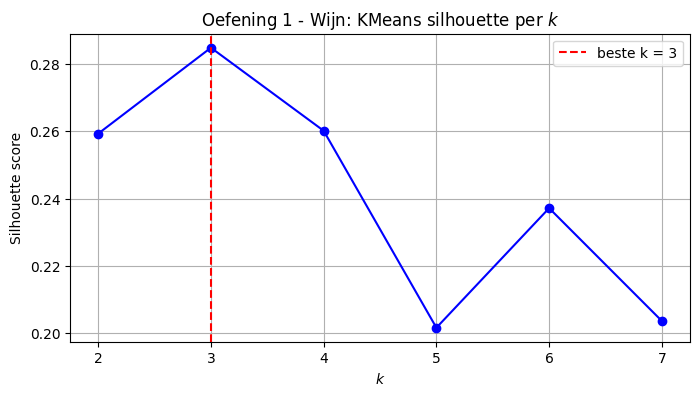

In [7]:
# TODO: bereken voor elke k in range(2, 8) de silhouette score (KMeans met
# random_state=42, n_init=10). Bewaar de k met de hoogste score in best_k_wine
# en die score in silhouette_wine.

import matplotlib.pyplot as plt

k_range_wine = list(range(2, 8))

best_k_wine = None
best_sil_score = -1
sil_scores = []

for k in k_range_wine:
    kmeans = KMeans(n_clusters= k, random_state=42, n_init=10)
    kmeans.fit(data_scaled)

    sil = silhouette_score(data_scaled, kmeans.labels_)
    sil_scores.append(sil)

    if sil > best_sil_score:
         best_k_wine = k
         best_sil_score = sil

    sil_score = best_sil_score

plt.figure(figsize=(8, 4))
plt.plot(k_range_wine, sil_scores, 'bo-')
plt.axvline(best_k_wine, color='red', linestyle='--', label=f'beste k = {best_k_wine}')
plt.xlabel('$k$')
plt.ylabel('Silhouette score')
plt.title('Oefening 1 - Wijn: KMeans silhouette per $k$')
plt.grid()
plt.legend()
plt.show()

## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [ ]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

In [ ]:
# TODO: train voor elk aantal kleuren een KMeans (random_state=42, n_init=10)
# op X, vervang elke pixel door de centroidkleur van zijn cluster en hervorm
# terug naar image.shape.
# Bewaar het tuple n_colors = (10, 8, 6, 4, 2) en de 5 gesegmenteerde
# afbeeldingen in segmented_imgs (zelfde vorm als image).

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

In [ ]:
# TODO: pas KMeans toe voor k in range(2, 6) en DBSCAN voor een aantal
# (eps, min_samples) combinaties, en vergelijk de silhouette scores.
# Bewaar de gekozen k in best_k_iris en de hoogste silhouette in silhouette_iris.

## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

In [ ]:
# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.

## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [ ]:
# Vraag 1: antwoord_iris = "A", "B", "C" of "D"
antwoord_iris = ""

# Vraag 2: antwoord_dbscan = "A", "B", "C" of "D"
antwoord_dbscan = ""
